# Customer Churn Prediction x Cell2Cell

## Project Overview

This notebook upgrades the existing IBM Telco analysis to the supplied Cell2Cell telecom churn data while retaining the original notebook in `churn_analysis_ibm_backup.ipynb`. It profiles the train and holdout files independently, preserves source rows and identifiers for tracing, and compares seven classifiers on one stratified test split.

The holdout file is an inference dataset: its `Churn` column is present but entirely missing. It is not used to evaluate models. All reported evaluation metrics come only from the held-out portion of the labeled training file. Preprocessing is fitted inside each model Pipeline using training rows only.

**Selection rule:** choose the model with the highest churn-class F1 score on the fixed test set; break ties by recall, ROC-AUC, precision, then accuracy. This balances missed churners with false alarms without treating accuracy as the sole objective.

In [17]:
from pathlib import Path
import shutil

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import xgboost
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, confusion_matrix, f1_score,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import ComplementNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, StandardScaler
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

# Resolve paths whether the notebook is started from the project root or notebooks/.
working_dir = Path.cwd()
NOTEBOOK_DIR = working_dir if working_dir.name == "notebooks" else working_dir / "notebooks"
if not NOTEBOOK_DIR.exists():
    raise FileNotFoundError(f"Could not locate notebooks/ from {working_dir}")
PROJECT_ROOT = NOTEBOOK_DIR.parent
DATASET_DIR = PROJECT_ROOT / "dataset"
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
TRAIN_PATH = DATASET_DIR / "cell2celltrain.csv"
HOLDOUT_PATH = DATASET_DIR / "cell2cellholdout.csv"
MODEL_PATH = MODEL_DIR / "churn_model.pkl"
MODEL_BACKUP_PATH = MODEL_DIR / "churn_model_ibm_backup.pkl"

print(f"Project root: {PROJECT_ROOT}")
print(f"pandas {pd.__version__} | scikit-learn {sklearn.__version__} | XGBoost {xgboost.__version__}")

Project root: c:\Users\dell\Downloads\Customer-Churn-Prediction
pandas 3.0.5 | scikit-learn 1.9.0 | XGBoost 3.4.1


## Dataset Loading

Load the Cell2Cell training and holdout CSVs independently. Record their unmodified shapes and complete column names before applying any modeling transformations.

In [18]:
for path in (TRAIN_PATH, HOLDOUT_PATH):
    if not path.is_file():
        raise FileNotFoundError(f"Required dataset file was not found: {path}")

train_data = pd.read_csv(TRAIN_PATH, low_memory=False)
holdout_data = pd.read_csv(HOLDOUT_PATH, low_memory=False)

ORIGINAL_TRAIN_SHAPE = train_data.shape
ORIGINAL_HOLDOUT_SHAPE = holdout_data.shape
print(f"Training file original shape: {ORIGINAL_TRAIN_SHAPE[0]:,} rows x {ORIGINAL_TRAIN_SHAPE[1]} columns")
print(f"Holdout file original shape: {ORIGINAL_HOLDOUT_SHAPE[0]:,} rows x {ORIGINAL_HOLDOUT_SHAPE[1]} columns")
print("Training columns:", train_data.columns.tolist())
print("Holdout columns:", holdout_data.columns.tolist())
print("\nTraining data types:\n", train_data.dtypes.to_string())
print("\nHoldout data types:\n", holdout_data.dtypes.to_string())

Training file original shape: 51,047 rows x 58 columns
Holdout file original shape: 20,000 rows x 58 columns
Training columns: ['CustomerID', 'Churn', 'MonthlyRevenue', 'MonthlyMinutes', 'TotalRecurringCharge', 'DirectorAssistedCalls', 'OverageMinutes', 'RoamingCalls', 'PercChangeMinutes', 'PercChangeRevenues', 'DroppedCalls', 'BlockedCalls', 'UnansweredCalls', 'CustomerCareCalls', 'ThreewayCalls', 'ReceivedCalls', 'OutboundCalls', 'InboundCalls', 'PeakCallsInOut', 'OffPeakCallsInOut', 'DroppedBlockedCalls', 'CallForwardingCalls', 'CallWaitingCalls', 'MonthsInService', 'UniqueSubs', 'ActiveSubs', 'ServiceArea', 'Handsets', 'HandsetModels', 'CurrentEquipmentDays', 'AgeHH1', 'AgeHH2', 'ChildrenInHH', 'HandsetRefurbished', 'HandsetWebCapable', 'TruckOwner', 'RVOwner', 'Homeownership', 'BuysViaMailOrder', 'RespondsToMailOffers', 'OptOutMailings', 'NonUSTravel', 'OwnsComputer', 'HasCreditCard', 'RetentionCalls', 'RetentionOffersAccepted', 'NewCellphoneUser', 'NotNewCellphoneUser', 'Referral

## Data Quality

Report completeness, exact duplicate rows, identifier uniqueness, target labels, and whether the two input schemas align. Missing values are retained for imputation in the Pipeline; rows are not dropped. `CustomerID` remains in the raw tables for traceability and is excluded only from model features.

In [19]:
def profile_dataset(frame, name):
    print(f"\n{name}: {frame.shape[0]:,} rows x {frame.shape[1]} columns")
    print(f"Exact duplicate rows: {int(frame.duplicated().sum()):,}")
    missing = frame.isna().sum()
    print(f"Missing cells: {int(missing.sum()):,}")
    print("Missing values by column (nonzero only):")
    print(missing[missing.gt(0)].to_string() if missing.any() else "None")
    if "CustomerID" in frame.columns:
        print(
            "CustomerID: "
            f"{frame['CustomerID'].nunique(dropna=True):,} unique; "
            f"{int(frame['CustomerID'].isna().sum()):,} missing; "
            f"{int(frame['CustomerID'].duplicated().sum()):,} repeated values"
        )
    if "Churn" in frame.columns:
        print("Churn values:", frame["Churn"].value_counts(dropna=False).to_dict())
        print(f"Non-missing Churn labels: {int(frame['Churn'].notna().sum()):,}")

profile_dataset(train_data, "Training file")
profile_dataset(holdout_data, "Holdout file")

if "Churn" not in train_data.columns:
    raise ValueError("Training data must contain the Churn target column.")
if train_data["Churn"].isna().any():
    raise ValueError("Training data contains missing Churn labels; resolve them before supervised training.")
labels = set(train_data["Churn"].astype(str).str.strip().unique())
if labels != {"Yes", "No"}:
    raise ValueError(f"Expected exactly the validated Yes/No target labels; found {sorted(labels)}")

holdout_has_observed_target = (
    "Churn" in holdout_data.columns and holdout_data["Churn"].notna().any()
)
print(f"\nHoldout has any observed target labels: {holdout_has_observed_target}")
if "CustomerID" in train_data.columns and "CustomerID" in holdout_data.columns:
    overlap = set(train_data["CustomerID"].dropna()).intersection(holdout_data["CustomerID"].dropna())
    print(f"CustomerID overlap between train and holdout: {len(overlap):,}")

train_predictors = [c for c in train_data.columns if c not in {"CustomerID", "Churn"}]
holdout_predictors = [c for c in holdout_data.columns if c not in {"CustomerID", "Churn"}]
if train_predictors != holdout_predictors:
    raise ValueError("Training and holdout predictor schemas differ; reconcile columns before inference.")
if holdout_has_observed_target:
    print("Observed holdout labels exist; this notebook still reserves evaluation for the stratified train/test split.")
else:
    print("Holdout Churn is entirely missing and will be reserved for inference only.")


Training file: 51,047 rows x 58 columns
Exact duplicate rows: 0
Missing cells: 3,515
Missing values by column (nonzero only):
MonthlyRevenue           156
MonthlyMinutes           156
TotalRecurringCharge     156
DirectorAssistedCalls    156
OverageMinutes           156
RoamingCalls             156
PercChangeMinutes        367
PercChangeRevenues       367
ServiceArea               24
Handsets                   1
HandsetModels              1
CurrentEquipmentDays       1
AgeHH1                   909
AgeHH2                   909
CustomerID: 51,047 unique; 0 missing; 0 repeated values
Churn values: {'No': 36336, 'Yes': 14711}
Non-missing Churn labels: 51,047

Holdout file: 20,000 rows x 58 columns
Exact duplicate rows: 0
Missing cells: 21,304
Missing values by column (nonzero only):
Churn                    20000
MonthlyRevenue              60
MonthlyMinutes              60
TotalRecurringCharge        60
DirectorAssistedCalls       60
OverageMinutes              60
RoamingCalls           

## Cleaning

No training rows or source columns are deleted: the inspected data has no exact duplicate rows, and its identifiers are unique. The target labels are validated before encoding. `CustomerID` and `Churn` are retained in the raw dataset but are never model inputs. Numeric and categorical missing values will be imputed separately inside the train-fitted preprocessing Pipeline.

In [20]:
# Keep untouched source frames for provenance; use a working copy for analysis.
clean_train = train_data.copy()
clean_holdout = holdout_data.copy()
clean_train["Churn"] = clean_train["Churn"].astype(str).str.strip()
clean_train_shape = clean_train.shape
print(f"Original training shape: {ORIGINAL_TRAIN_SHAPE}")
print(f"Final cleaned training shape: {clean_train_shape}")
print(f"Rows removed: {ORIGINAL_TRAIN_SHAPE[0] - clean_train_shape[0]}")
print(f"Columns removed from source copy: {ORIGINAL_TRAIN_SHAPE[1] - clean_train_shape[1]}")
print("Cleaning decision: no rows or source columns removed; identifiers/target are excluded only when constructing X.")

Original training shape: (51047, 58)
Final cleaned training shape: (51047, 58)
Rows removed: 0
Columns removed from source copy: 0
Cleaning decision: no rows or source columns removed; identifiers/target are excluded only when constructing X.


## EDA

Plots below describe the labeled training data. Associations are descriptive, not causal. The holdout file is not mixed into model-training EDA.

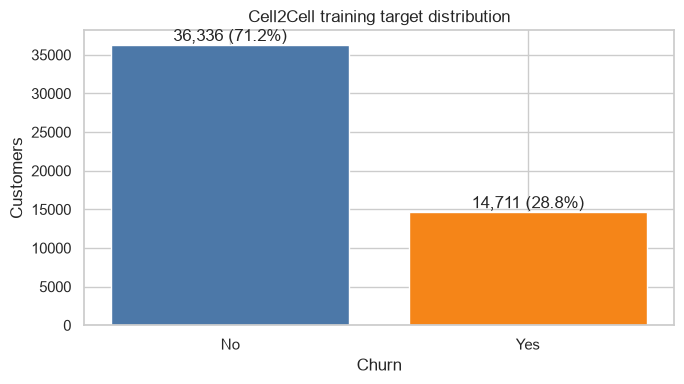

Observation: churn prevalence is 28.82%; the class distribution is imbalanced.


In [21]:
churn_counts = clean_train["Churn"].value_counts().reindex(["No", "Yes"], fill_value=0)
churn_percent = churn_counts / churn_counts.sum() * 100
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(churn_counts.index, churn_counts.values, color=["#4C78A8", "#F58518"])
ax.bar_label(bars, labels=[f"{count:,} ({pct:.1f}%)" for count, pct in zip(churn_counts, churn_percent)])
ax.set(title="Cell2Cell training target distribution", xlabel="Churn", ylabel="Customers")
plt.tight_layout()
plt.show()
print(f"Observation: churn prevalence is {churn_percent['Yes']:.2f}%; the class distribution is imbalanced.")

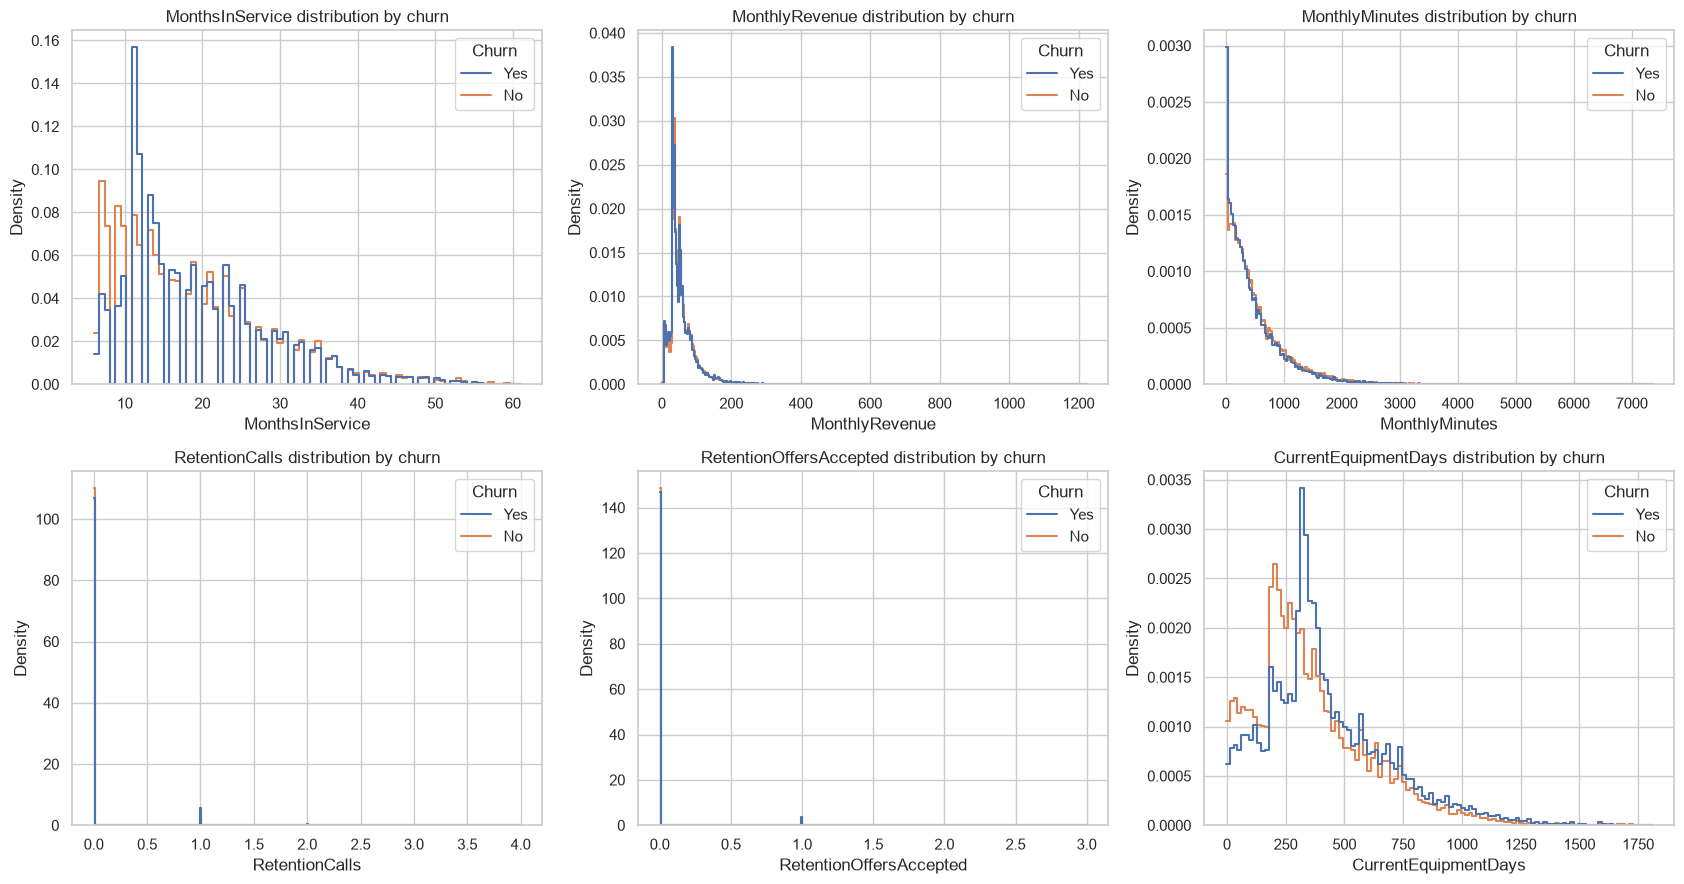

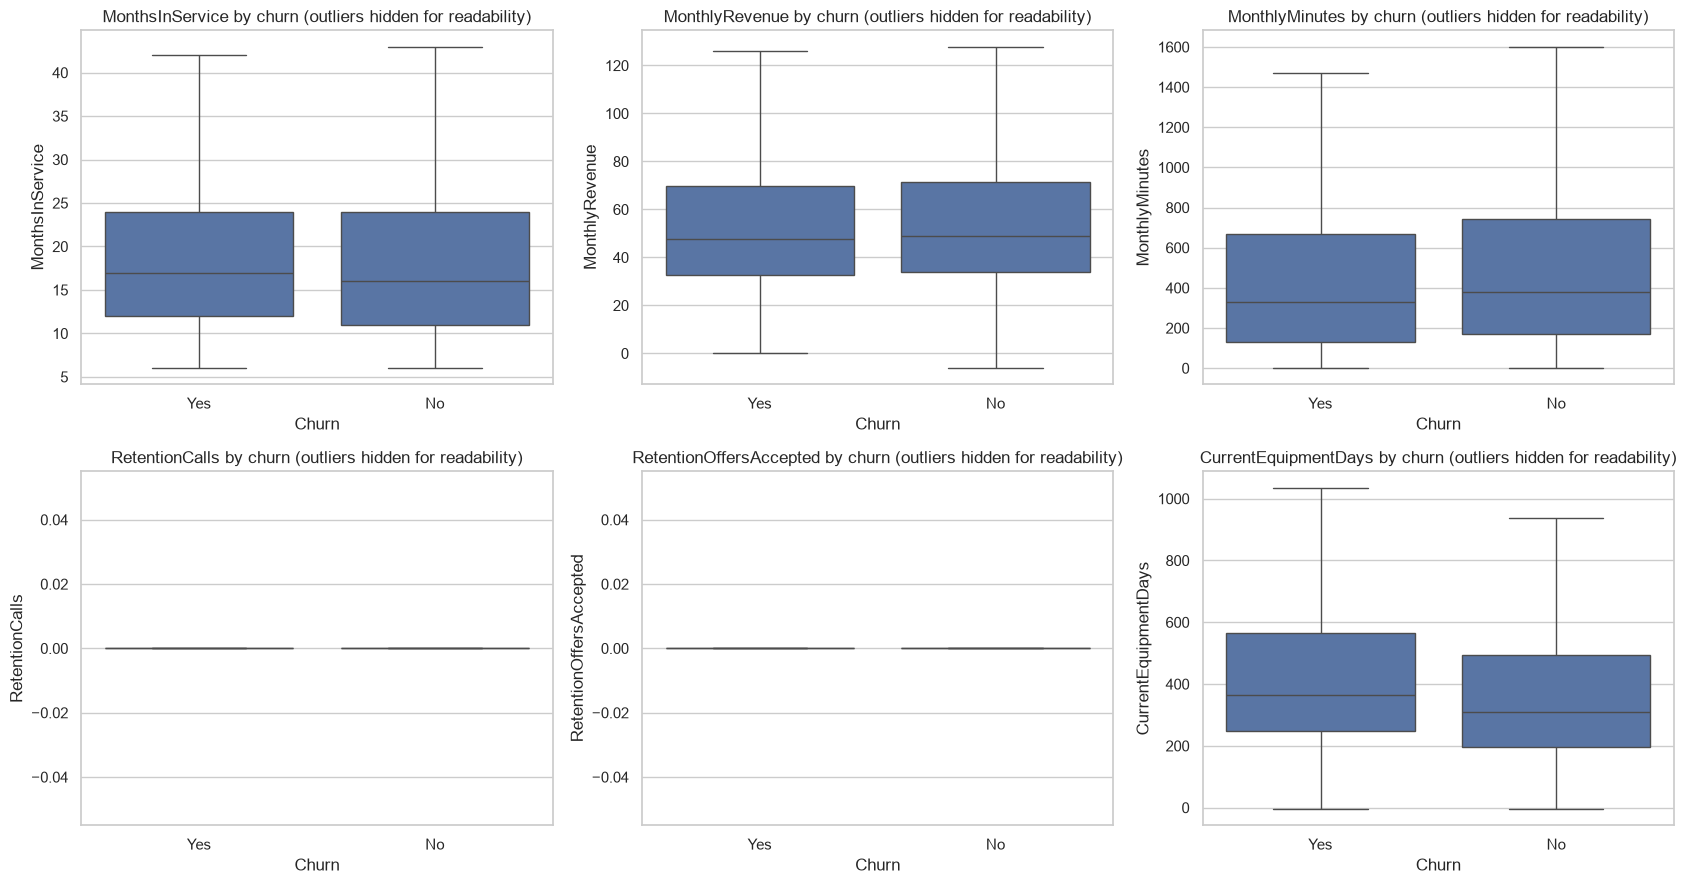

Observation: these plots compare tenure, revenue, usage, retention activity, and equipment age by target; inspect medians and overlap rather than treating differences as causal.


In [22]:
numeric_for_eda = [
    col for col in clean_train.select_dtypes(include="number").columns
    if col != "CustomerID"
]
feature_highlights = [
    "MonthsInService", "MonthlyRevenue", "MonthlyMinutes",
    "RetentionCalls", "RetentionOffersAccepted", "CurrentEquipmentDays",
]
feature_highlights = [c for c in feature_highlights if c in numeric_for_eda]

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, feature in zip(axes.flat, feature_highlights):
    sns.histplot(
        data=clean_train, x=feature, hue="Churn", stat="density",
        common_norm=False, element="step", fill=False, ax=ax
    )
    ax.set_title(f"{feature} distribution by churn")
for ax in axes.flat[len(feature_highlights):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, feature in zip(axes.flat, feature_highlights):
    sns.boxplot(data=clean_train, x="Churn", y=feature, showfliers=False, ax=ax)
    ax.set_title(f"{feature} by churn (outliers hidden for readability)")
for ax in axes.flat[len(feature_highlights):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()
print("Observation: these plots compare tenure, revenue, usage, retention activity, and equipment age by target; inspect medians and overlap rather than treating differences as causal.")

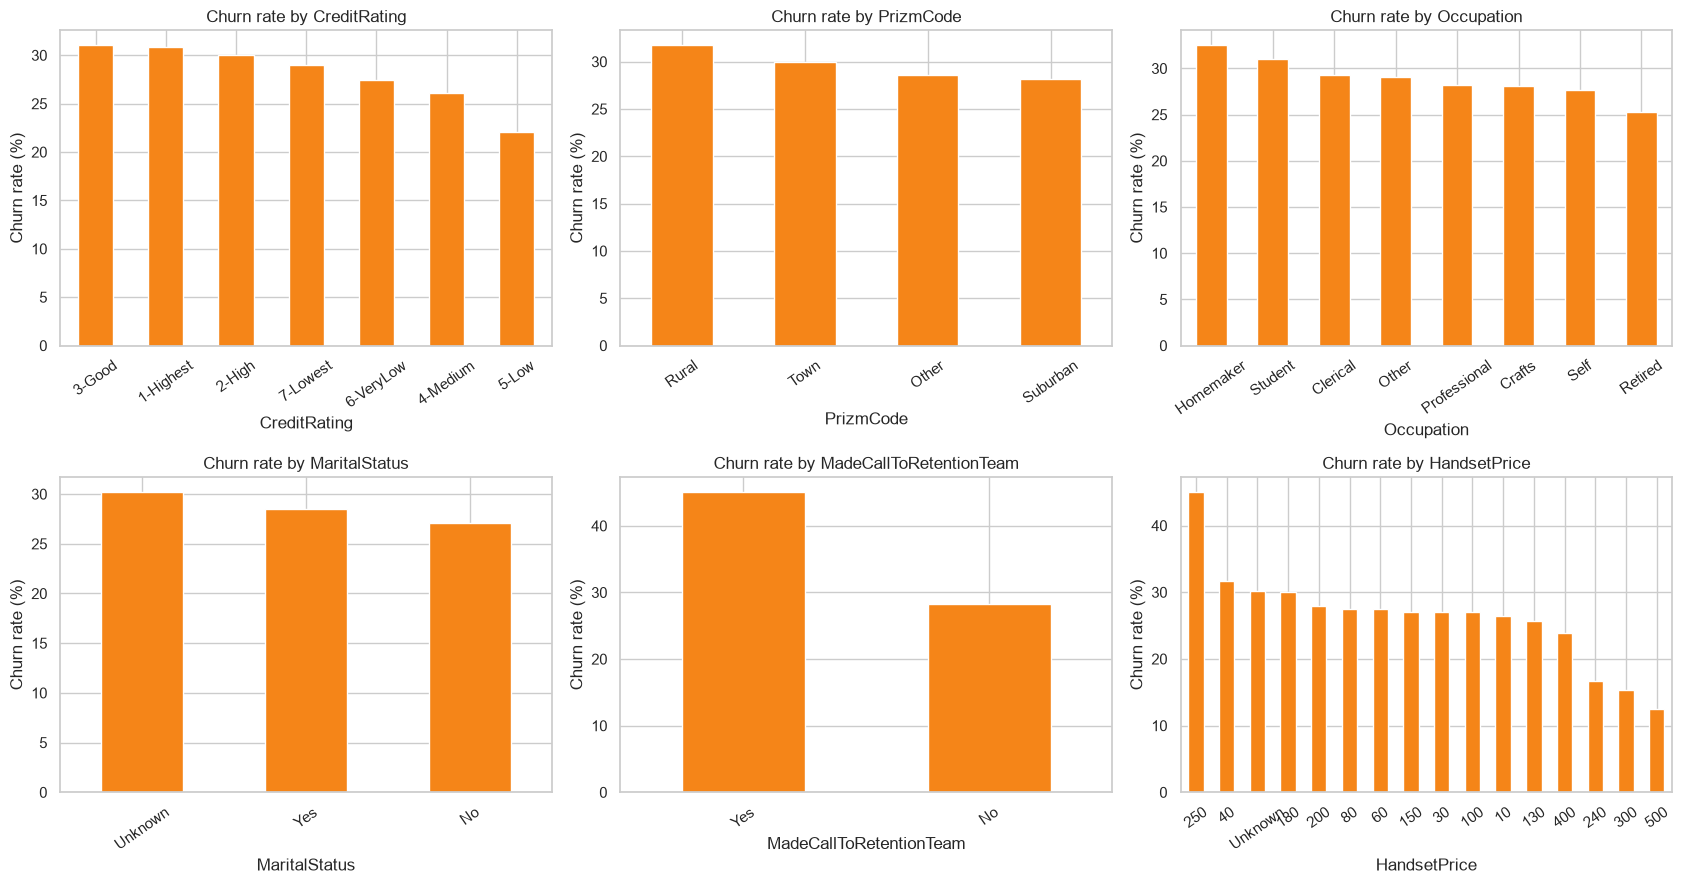

Observation: category-level churn rates are descriptive. ServiceArea is omitted from this chart because its 747 training categories make a readable plot impractical.


In [23]:
categorical_highlights = [
    c for c in ["CreditRating", "PrizmCode", "Occupation", "MaritalStatus", "MadeCallToRetentionTeam", "HandsetPrice"]
    if c in clean_train.columns and clean_train[c].nunique(dropna=True) <= 20
]
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, feature in zip(axes.flat, categorical_highlights):
    rates = clean_train.groupby(feature, dropna=False, observed=True)["Churn"].apply(lambda s: (s == "Yes").mean() * 100)
    rates.sort_values(ascending=False).plot(kind="bar", ax=ax, color="#F58518")
    ax.set(title=f"Churn rate by {feature}", xlabel=feature, ylabel="Churn rate (%)")
    ax.tick_params(axis="x", labelrotation=35)
for ax in axes.flat[len(categorical_highlights):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()
print("Observation: category-level churn rates are descriptive. ServiceArea is omitted from this chart because its 747 training categories make a readable plot impractical.")

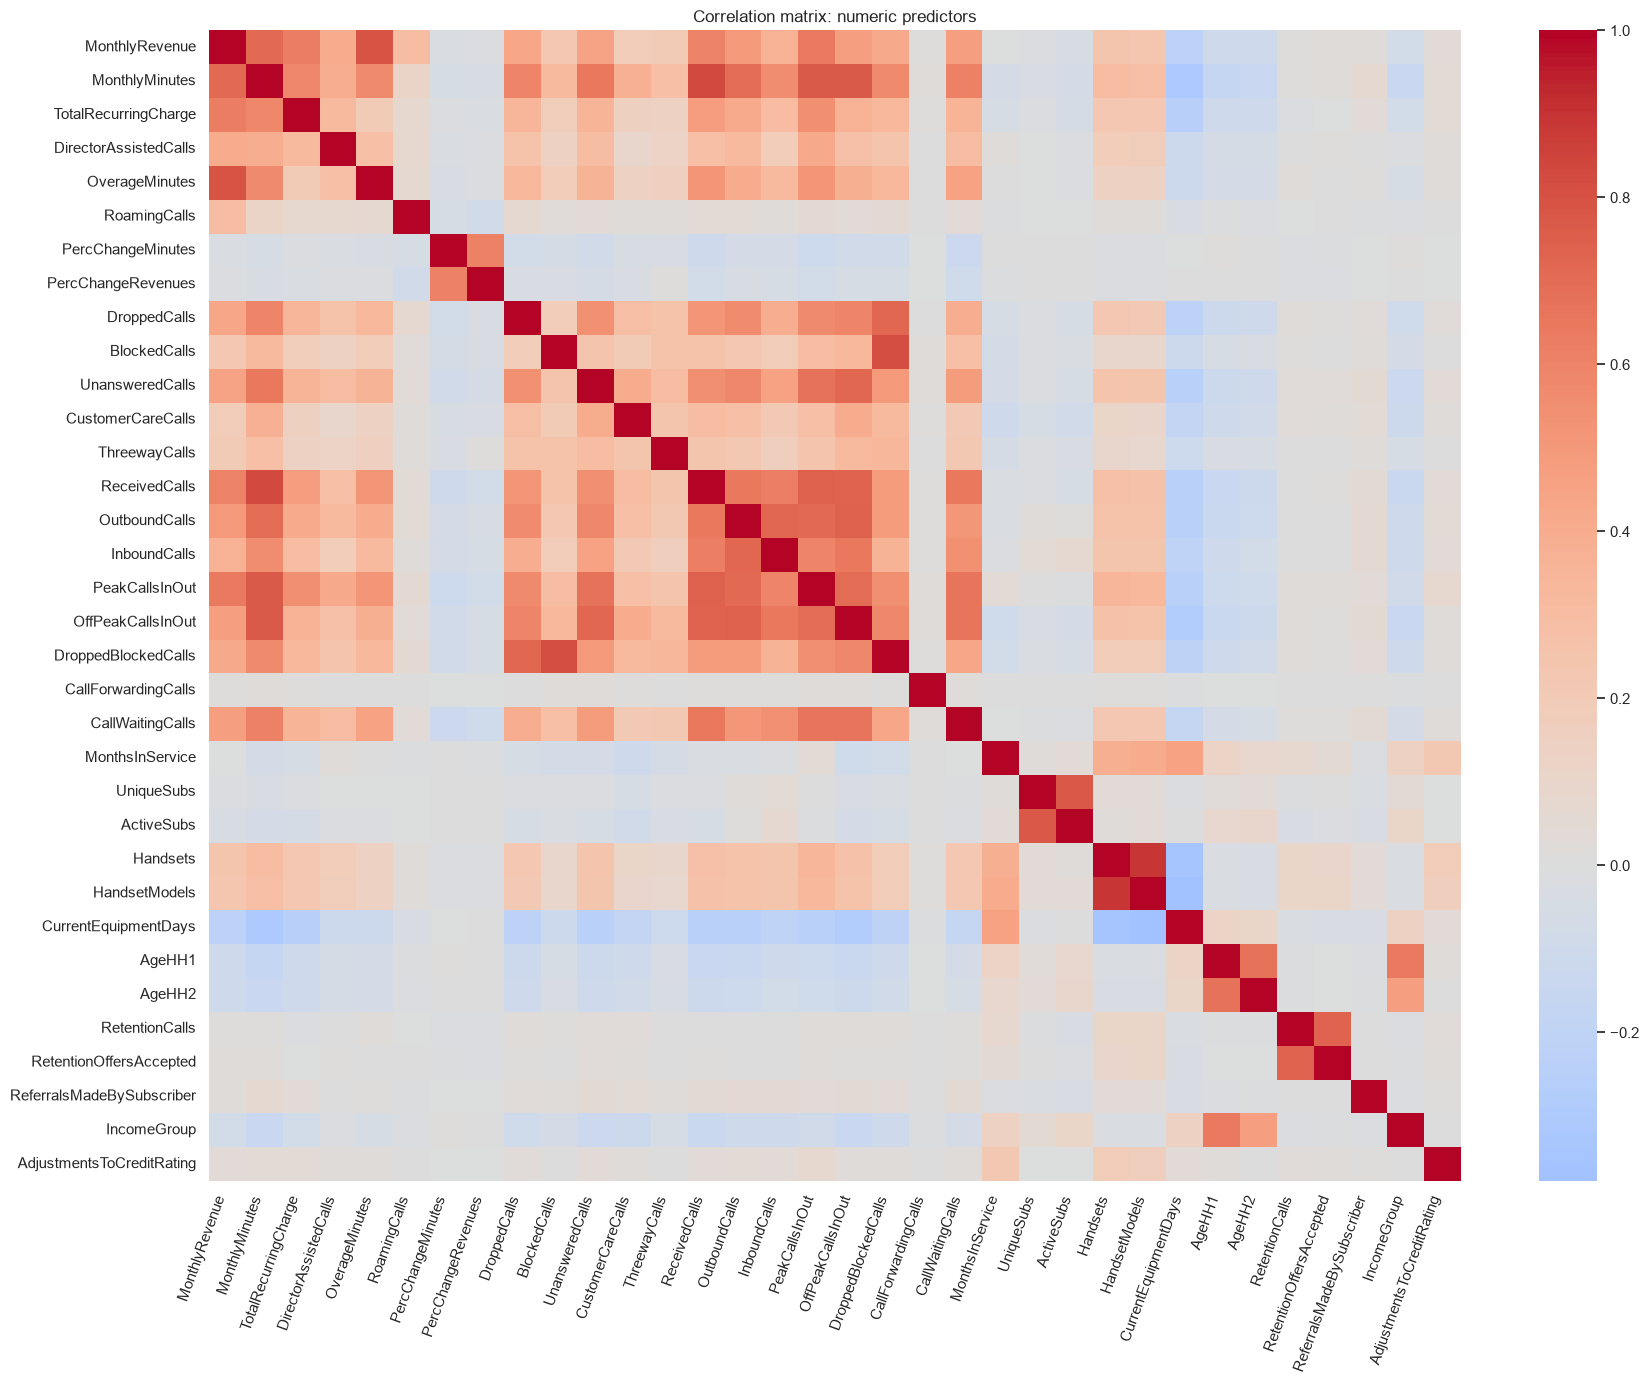

Observation: correlations are among numeric predictors only; CustomerID and the categorical Churn target are excluded.


In [24]:
correlation_features = [c for c in numeric_for_eda if clean_train[c].nunique(dropna=True) > 1]
correlations = clean_train[correlation_features].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(18, 14))
sns.heatmap(correlations, cmap="coolwarm", center=0, ax=ax, xticklabels=True, yticklabels=True)
ax.set_title("Correlation matrix: numeric predictors")
plt.xticks(rotation=70, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()
print("Observation: correlations are among numeric predictors only; CustomerID and the categorical Churn target are excluded.")

## Preprocessing

Separate the validated target from predictors and remove `CustomerID` only from `X`. Use median imputation plus standardization for numeric features, and most-frequent imputation plus one-hot encoding for categorical features. `ServiceArea` has many levels, so infrequent levels are grouped with a documented minimum frequency; unseen values at prediction time are ignored. Pipelines ensure every imputer, scaler, and encoder is fitted only on its training fold.

In [25]:
target_map = {"No": 0, "Yes": 1}
X = clean_train.drop(columns=["Churn", "CustomerID"], errors="ignore").copy()
y = clean_train["Churn"].map(target_map).astype("int8")
if "Churn" in X.columns or "CustomerID" in X.columns:
    raise AssertionError("Target leakage or identifier leakage detected in X.")

numeric_features = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c].dtype)]
categorical_features = [c for c in X.columns if c not in numeric_features]
if set(numeric_features).union(categorical_features) != set(X.columns):
    raise AssertionError("Every model feature must be assigned to exactly one preprocessing branch.")
print(f"Final modeling matrix before encoding: {X.shape}")
print(f"Numeric features ({len(numeric_features)}): {numeric_features}")
print(f"Categorical features ({len(categorical_features)}): {categorical_features}")
print(f"Target counts (0=No, 1=Yes): {y.value_counts().sort_index().to_dict()}")
print(f"Majority/minority ratio: {y.value_counts().max() / y.value_counts().min():.2f}:1")

Final modeling matrix before encoding: (51047, 56)
Numeric features (34): ['MonthlyRevenue', 'MonthlyMinutes', 'TotalRecurringCharge', 'DirectorAssistedCalls', 'OverageMinutes', 'RoamingCalls', 'PercChangeMinutes', 'PercChangeRevenues', 'DroppedCalls', 'BlockedCalls', 'UnansweredCalls', 'CustomerCareCalls', 'ThreewayCalls', 'ReceivedCalls', 'OutboundCalls', 'InboundCalls', 'PeakCallsInOut', 'OffPeakCallsInOut', 'DroppedBlockedCalls', 'CallForwardingCalls', 'CallWaitingCalls', 'MonthsInService', 'UniqueSubs', 'ActiveSubs', 'Handsets', 'HandsetModels', 'CurrentEquipmentDays', 'AgeHH1', 'AgeHH2', 'RetentionCalls', 'RetentionOffersAccepted', 'ReferralsMadeBySubscriber', 'IncomeGroup', 'AdjustmentsToCreditRating']
Categorical features (22): ['ServiceArea', 'ChildrenInHH', 'HandsetRefurbished', 'HandsetWebCapable', 'TruckOwner', 'RVOwner', 'Homeownership', 'BuysViaMailOrder', 'RespondsToMailOffers', 'OptOutMailings', 'NonUSTravel', 'OwnsComputer', 'HasCreditCard', 'NewCellphoneUser', 'NotNew

## Train-Test Split

Use one fixed 80/20 split with stratification. The test rows are held aside before any preprocessing is fitted and are shared by every model.

In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
print(f"Training rows: {len(X_train):,}; test rows: {len(X_test):,}")
print("Training target proportions:", y_train.value_counts(normalize=True).sort_index().round(4).to_dict())
print("Test target proportions:", y_test.value_counts(normalize=True).sort_index().round(4).to_dict())

Training rows: 40,837; test rows: 10,210
Training target proportions: {0: 0.7118, 1: 0.2882}
Test target proportions: {0: 0.7119, 1: 0.2881}


## Model Training

All models use the same split and input fields. Class weighting is applied to several classifiers to address the minority churn class. A linear SVM is used rather than a quadratic-cost kernel SVM for this 51k-row dataset; calibration provides probabilities for ROC-AUC and downstream predictions. Complement Naive Bayes uses a non-negative numeric scaling branch, which is appropriate for its input assumptions.

In [27]:
def make_preprocessor(numeric_scaler):
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", numeric_scaler),
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=20)),
    ])
    return ColumnTransformer([
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features),
    ])

positive_weight = float((y_train == 0).sum() / (y_train == 1).sum())
classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=1500, class_weight="balanced", random_state=SEED),
    "Decision Tree": DecisionTreeClassifier(max_depth=12, min_samples_leaf=20, class_weight="balanced", random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=250, max_depth=18, min_samples_leaf=5, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
    "K-Nearest Neighbours": KNeighborsClassifier(n_neighbors=11, weights="distance", algorithm="brute", n_jobs=-1),
    "Naive Bayes (Complement)": ComplementNB(),
    "Support Vector Machine (linear, calibrated)": CalibratedClassifierCV(
        estimator=LinearSVC(class_weight="balanced", max_iter=5000, dual="auto", random_state=SEED),
        method="sigmoid", cv=3, n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        objective="binary:logistic", eval_metric="logloss", n_estimators=250,
        max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
        scale_pos_weight=positive_weight, tree_method="hist", n_jobs=4,
        random_state=SEED,
    ),
}

pipelines = {}
for name, classifier in classifiers.items():
    scaler = MinMaxScaler() if name == "Naive Bayes (Complement)" else StandardScaler()
    pipelines[name] = Pipeline([
        ("preprocessor", make_preprocessor(scaler)),
        ("classifier", classifier),
    ])
print(f"Prepared {len(pipelines)} model Pipelines; positive-class weight for XGBoost: {positive_weight:.3f}")

Prepared 7 model Pipelines; positive-class weight for XGBoost: 2.470


In [12]:
metric_rows = []
confusion_matrices = {}
for name, pipeline in pipelines.items():
    print(f"Fitting {name}...")
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]
    metric_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
    })
    confusion_matrices[name] = confusion_matrix(y_test, predictions, labels=[0, 1])

metrics = pd.DataFrame(metric_rows).set_index("Model")
metrics = metrics.sort_values(["F1", "Recall", "ROC-AUC", "Precision", "Accuracy"], ascending=False)
print("All evaluation metrics below are measured on the same held-out test split.")
display(metrics.style.format("{:.3f}"))

Fitting Logistic Regression...
Fitting Decision Tree...
Fitting Random Forest...
Fitting K-Nearest Neighbours...
Fitting Naive Bayes (Complement)...
Fitting Support Vector Machine (linear, calibrated)...
Fitting XGBoost...
All evaluation metrics below are measured on the same held-out test split.


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
XGBoost,0.626,0.405,0.635,0.494,0.677
Random Forest,0.658,0.418,0.478,0.446,0.659
Decision Tree,0.587,0.363,0.571,0.444,0.608
Logistic Regression,0.579,0.356,0.574,0.440,0.611
Naive Bayes (Complement),0.568,0.337,0.516,0.408,0.576
K-Nearest Neighbours,0.693,0.375,0.099,0.157,0.571
"Support Vector Machine (linear, calibrated)",0.713,0.549,0.017,0.033,0.610


## Model Comparison

Compare churn-class precision, recall, and F1 alongside accuracy and ROC-AUC. Because churn is the minority class, accuracy alone can conceal missed churners. Confusion matrices use the same held-out observations for every model.

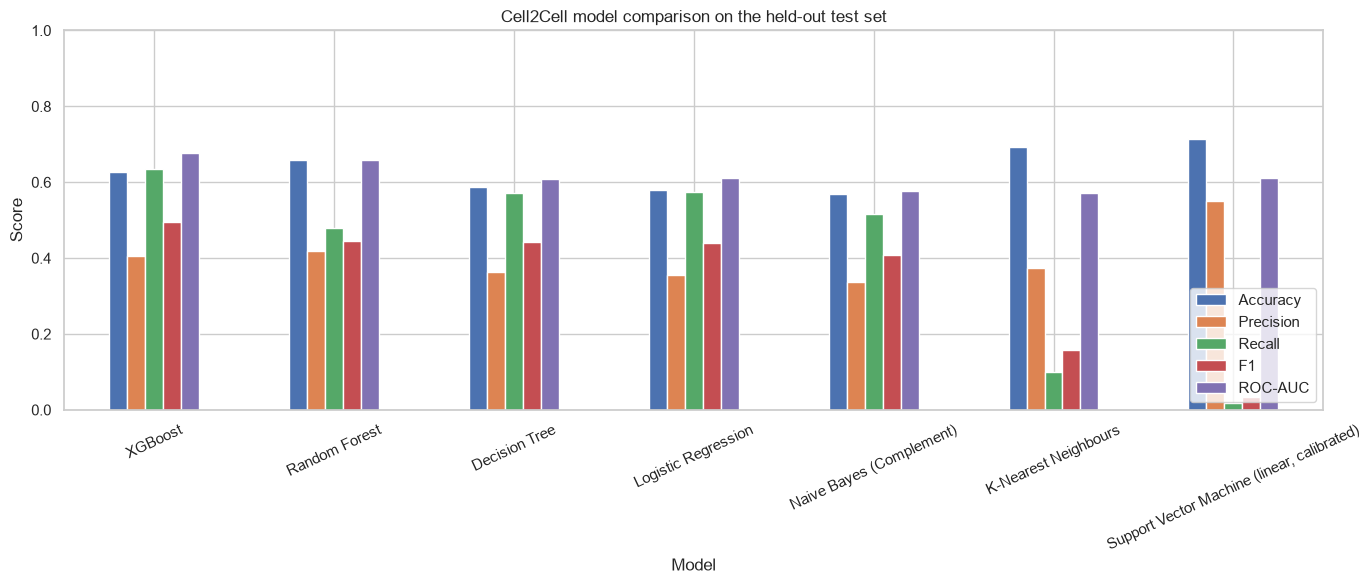

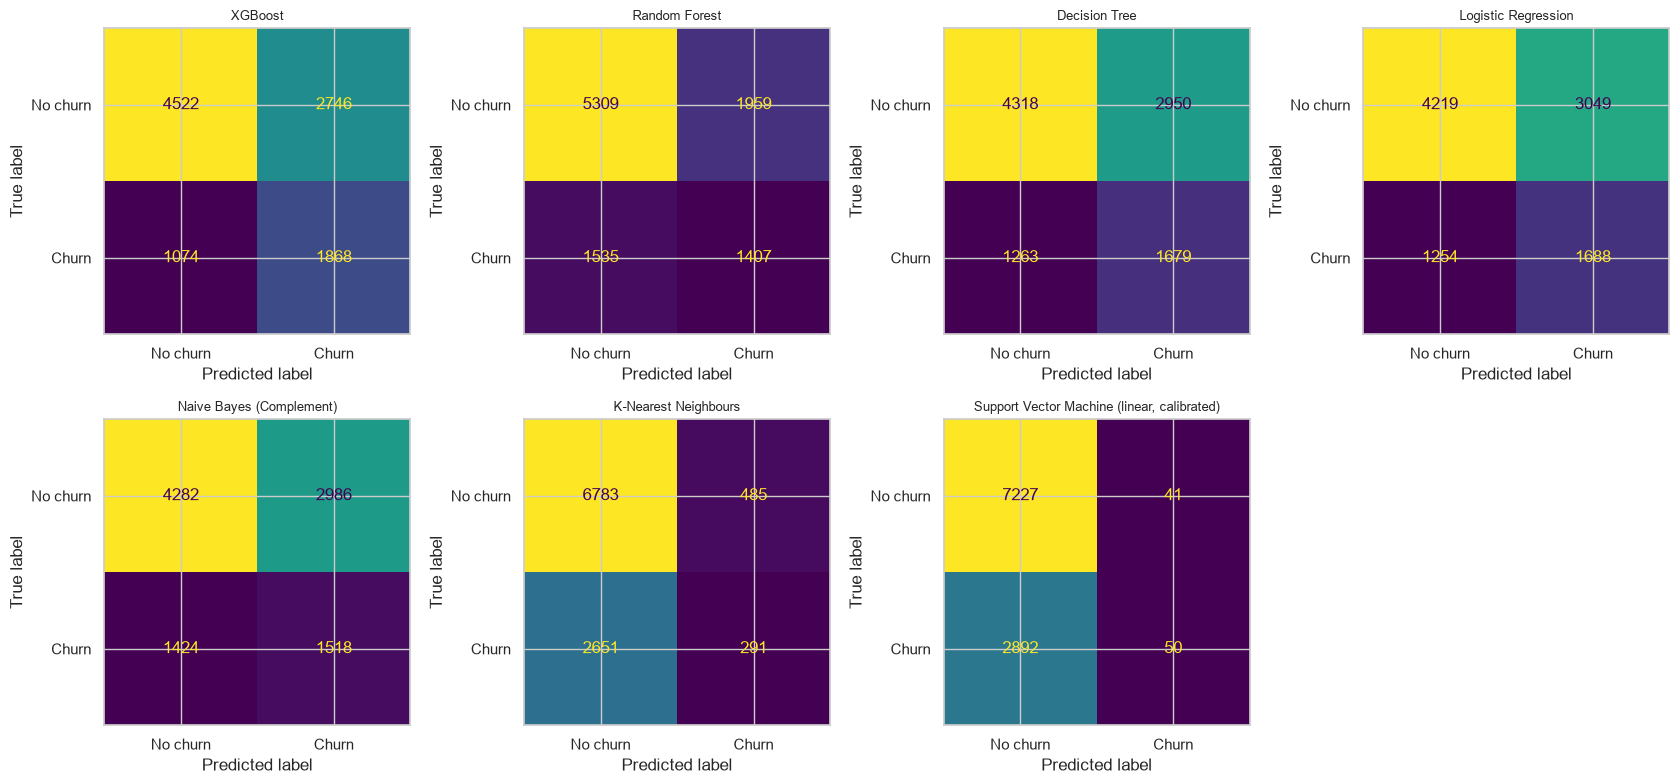

In [28]:
metrics[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]].plot(
    kind="bar", figsize=(14, 6), ylim=(0, 1), rot=25
)
plt.title("Cell2Cell model comparison on the held-out test set")
plt.ylabel("Score")
plt.xlabel("Model")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for ax, name in zip(axes.flat, metrics.index):
    ConfusionMatrixDisplay(confusion_matrix=confusion_matrices[name], display_labels=["No churn", "Churn"]).plot(
        ax=ax, colorbar=False, values_format="d"
    )
    ax.set_title(name, fontsize=9)
for ax in axes.flat[len(metrics):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

## Final Evaluation

Select by churn-class F1, then recall, ROC-AUC, precision, and accuracy. All metrics use the default classifier decision threshold and the same test split; no performance claim is made relative to the prior IBM dataset.

In [29]:
final_model_name = metrics.index[0]
final_pipeline = pipelines[final_model_name]
final_predictions = final_pipeline.predict(X_test)
final_probabilities = final_pipeline.predict_proba(X_test)[:, 1]
final_metrics = metrics.loc[final_model_name]
final_matrix = confusion_matrices[final_model_name]

print(f"Selected model: {final_model_name}")
print("Selection criteria: highest churn F1; ties resolved by recall, ROC-AUC, precision, then accuracy.")
print(final_metrics.to_string(float_format=lambda value: f"{value:.4f}"))
print("Confusion matrix [rows=true, columns=predicted; labels 0=No, 1=Yes]:")
print(final_matrix)
print(f"Churn cases missed (false negatives): {final_matrix[1, 0]:,}")
print(f"False churn alerts (false positives): {final_matrix[0, 1]:,}")

NotFittedError: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.

## Save Final Model

Save the entire fitted Pipeline so imputation, scaling, encoding, and prediction remain consistent in the app. The IBM Pipeline was backed up before replacing the shared `churn_model.pkl` path; the notebook also checks for a backup before overwriting an existing artifact.

In [ ]:
if MODEL_PATH.exists() and not MODEL_BACKUP_PATH.exists():
    shutil.copy2(MODEL_PATH, MODEL_BACKUP_PATH)
    print(f"Backed up the pre-existing model to {MODEL_BACKUP_PATH}")

joblib.dump(final_pipeline, MODEL_PATH)
print(f"Saved complete fitted Pipeline: {MODEL_PATH}")
print(f"Expected input feature count: {len(final_pipeline.feature_names_in_)}")
print("Target mapping: No x 0, Yes x 1")

Saved complete fitted Pipeline: c:\Users\dell\Downloads\Customer-Churn-Prediction\models\churn_model.pkl
Expected input feature count: 56
Target mapping: No x 0, Yes x 1


## Holdout Inference

The holdout has no observed churn labels, so predictions are illustrative outputs only and are not evaluation results. Preserve `CustomerID` beside predictions for record tracing; never pass it to the model.

In [ ]:
holdout_X = clean_holdout.drop(columns=["Churn", "CustomerID"], errors="ignore")
if list(holdout_X.columns) != list(final_pipeline.feature_names_in_):
    raise ValueError("Holdout feature order/schema does not match the saved model.")
holdout_predictions = pd.DataFrame({
    "CustomerID": clean_holdout["CustomerID"].to_numpy() if "CustomerID" in clean_holdout else np.arange(len(clean_holdout)),
    "PredictedChurn": final_pipeline.predict(holdout_X),
    "ChurnProbability": final_pipeline.predict_proba(holdout_X)[:, 1],
})
holdout_predictions["PredictedChurn"] = holdout_predictions["PredictedChurn"].map({0: "No", 1: "Yes"})
print(f"Generated predictions for {len(holdout_predictions):,} unlabeled holdout rows; no holdout metric was calculated.")
display(holdout_predictions.head())

Generated predictions for 20,000 unlabeled holdout rows; no holdout metric was calculated.


,CustomerID,PredictedChurn,ChurnProbability
0,3000006,No,0.224732
1,3000018,No,0.353508
2,3000034,No,0.452189
3,3000070,No,0.303931
4,3000074,No,0.216917


## Conclusion

This workflow profiles both supplied files, preserves source data and identifiers, excludes identifiers and target labels from model inputs, imputes missing values within train-fitted Pipelines, and evaluates seven classifiers on a shared stratified test split. Use the measured comparison table above to interpret the selected model; churn recall and precision should be considered with F1, ROC-AUC, accuracy, and the false-negative/false-positive counts. The holdout predictions are not labeled ground truth.